# 02 — Volatility forecasting (Phase B, C, D)

**Problem:** On day *t*, forecast the realized volatility of the next 5 trading sessions (t+1 … t+5).

- **Phase B:** Target, statistical baselines, leakage checks, and time-based splits
- **Phase C:** Ridge and Random Forest (tuned on the validation set)
- **Phase D:** Test-set evaluation, plots, error analysis, and interpretation

> This is an educational research project, not investment advice or a trading system.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

def find_root(start=None):
    """Auto-detect the project root directory (where src/data.py is located), independent of the working directory."""
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "data.py").exists():
            return p
    raise FileNotFoundError(
        "Project directory not found (requires src/data.py). "
        "Please open the notebook from inside the vn-index-volatility-research/ directory while preserving the folder structure."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT))
from src.data import load_vnindex, find_data_file

# ===================== CONFIG: locked BEFORE viewing test results =====================
DATA_PATH = find_data_file(ROOT)  # defaults to data/vnindex.csv; or the single .csv file in data/
print("Reading data from:", DATA_PATH)
H = 5                              # horizon: number of future trading days
TRAIN_FRAC, VAL_FRAC = 0.60, 0.20  # remaining part (last ~20%) is test
TRAIN_END_DATE = None              # or "2017-12-31" to fix cutoff date
VAL_END_DATE = None                # or "2020-12-31"
LOG_TARGET = True                  # ML predicts log(vol) then exps back (vol is heavily right-skewed)
SEED = 42
# ===================================================================================

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})


def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

Reading data from: D:\Uni\Time-Series_Research_Project\vn-index-volatility-research\data\vnindex.csv


In [21]:
df = load_vnindex(DATA_PATH)
invalid_close = df[(df["close"] > df["high"]) | (df["close"] < df["low"])]
print("Close outside [Low, High]:", len(invalid_close))
if not invalid_close.empty:
    print("WARNING: These observations are retained without adjustment, as in the EDA notebook.")
    display(invalid_close[["close", "low", "high"]])

df["log_ret"] = np.log(df["close"] / df["close"].shift(1))
df = df.dropna(subset=["log_ret"])
print(df.shape, df.index.min().date(), "→", df.index.max().date())

Close outside [Low, High]: 1


,close,low,high
date,,,
2005-12-20,311.83,313.66,314.22


(5931, 7) 2000-08-02 → 2024-12-16


# Phase B — Statistical baseline
## B1. Target: realized volatility over the next H sessions
`rolling(H).std()` at day t+H uses returns from t+1…t+H. `shift(-H)` moves that value back to day t.
Thus, at day t, the target lies entirely in the future. This is **daily volatility, not annualized**.

In [3]:
def build_target(r, h=H):
    return r.rolling(h).std().shift(-h)


df["target_vol"] = build_target(df["log_ret"])

# Manual check: target at position pos must equal std of returns pos+1 … pos+H
rng = np.random.default_rng(0)
for pos in rng.integers(0, len(df) - H - 1, 5):
    manual = df["log_ret"].iloc[pos + 1: pos + 1 + H].std()
    assert np.isclose(manual, df["target_vol"].iloc[pos]), pos
print("Target alignment OK. NaNs at the end of series:", int(df["target_vol"].isna().sum()), "(= H, as expected)")

Target alignment OK. NaNs at the end of series: 5 (= H, as expected)


## B2. Statistical baselines (using information available through day t only)
- `base_5`, `base_20`: standard deviation of the most recent 5 / 20 returns
- `base_exp`: standard deviation of all history through t (expanding)
- `base_ewma`: RiskMetrics EWMA (λ = 0.94), a classic baseline

In [4]:
def build_baselines(r):
    b = pd.DataFrame(index=r.index)
    b["base_5"] = r.rolling(5).std()
    b["base_20"] = r.rolling(20).std()
    b["base_exp"] = r.expanding(min_periods=60).std()
    ewma = np.sqrt((r ** 2).ewm(alpha=0.06, adjust=False).mean())
    ewma.iloc[:60] = np.nan 
    b["base_ewma"] = ewma
    return b

## B3. ML features (shared here so all models use the same set of valid rows)
Rule: features for day t use data only through the end of day t (rolling / positive shifts; never `shift(-k)`).
In addition to the list in the README, `hl_range` = log(High/Low) is included to capture the intraday range using the High/Low columns.

In [5]:
def build_features(d):
    r = d["log_ret"]
    f = pd.DataFrame(index=d.index)
    for k in (1, 2, 5, 10):
        f[f"ret_lag{k}"] = r.shift(k - 1)         
    for w in (5, 10, 20):
        f[f"std_{w}"] = r.rolling(w).std()
    for w in (5, 20):
        f[f"mean_{w}"] = r.rolling(w).mean()
    f["abs_ret"] = r.abs()
    f["abs_ret_5"] = r.abs().rolling(5).mean()
    for w in (20, 60):
        f[f"dist_ma{w}"] = d["close"] / d["close"].rolling(w).mean() - 1
    hl = np.log(d["high"] / d["low"])
    f["hl_range"] = hl
    f["hl_range_5"] = hl.rolling(5).mean()
    return f


feat = build_features(df)
base = build_baselines(df["log_ret"])
FEATURES, BASELINES = list(feat.columns), list(base.columns)
print("Features:", FEATURES)

Features: ['ret_lag1', 'ret_lag2', 'ret_lag5', 'ret_lag10', 'std_5', 'std_10', 'std_20', 'mean_5', 'mean_20', 'abs_ret', 'abs_ret_5', 'dist_ma20', 'dist_ma60', 'hl_range', 'hl_range_5']


## B4. Leakage check by truncating the data
If a feature or baseline for day t truly uses only past information, calculating it on data truncated at t
must produce **exactly the same value** as calculating it on the full dataset.

In [6]:
n = len(df)
for pos in [n // 4, n // 2, 3 * n // 4, n - 1]:
    cut = df.iloc[: pos + 1]
    f_cut = build_features(cut).iloc[-1].values
    b_cut = build_baselines(cut["log_ret"]).iloc[-1].values
    assert np.allclose(f_cut, feat.iloc[pos].values, equal_nan=True), f"Feature leakage at position {pos}"
    assert np.allclose(b_cut, base.iloc[pos].values, equal_nan=True), f"Baseline leakage at position {pos}"
print("No look-ahead detected in features and baselines.")

No look-ahead detected in features and baselines.


## B5. Time-based train / validation / test split with an H-session purge
Targets for the final H rows of each split use returns from the following split → drop the final H rows of the training and validation sets.

train: 2000-12-22 → 2015-07-17  (n=3514)
val  : 2015-07-27 → 2020-03-25  (n=1168)
test : 2020-04-03 → 2024-12-09  (n=1174)


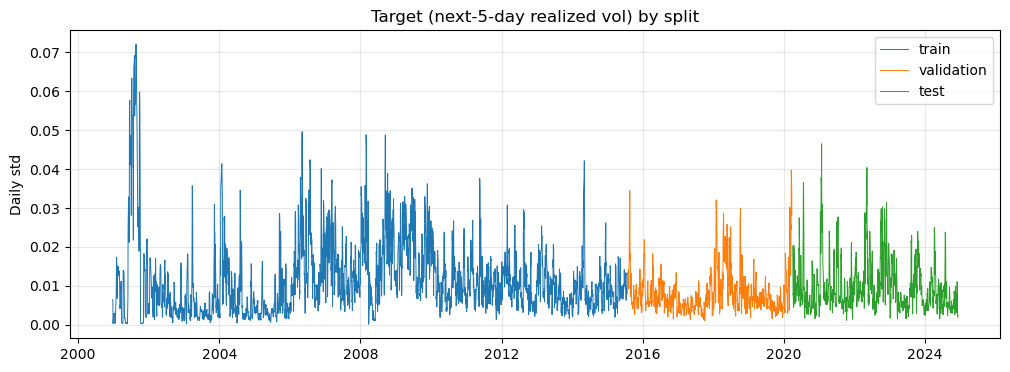

In [7]:
data = pd.concat([feat, base, df["target_vol"]], axis=1).dropna()

if TRAIN_END_DATE:
    i1 = data.index.searchsorted(pd.Timestamp(TRAIN_END_DATE), side="right")
else:
    i1 = int(len(data) * TRAIN_FRAC)
if VAL_END_DATE:
    i2 = data.index.searchsorted(pd.Timestamp(VAL_END_DATE), side="right")
else:
    i2 = int(len(data) * (TRAIN_FRAC + VAL_FRAC))

train = data.iloc[: i1 - H]
val = data.iloc[i1: i2 - H]
test = data.iloc[i2:]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {part.index.min().date()} → {part.index.max().date()}  (n={len(part)})")

fig, ax = plt.subplots()
for part, label in [(train, "train"), (val, "validation"), (test, "test")]:
    ax.plot(part.index, part["target_vol"], lw=0.7, label=label)
ax.set(title="Target (next-5-day realized vol) by split", ylabel="Daily std")
ax.legend()
savefig("06_split.png")
plt.show()

## B6. Evaluate baselines on the validation set
Metrics: MAE, RMSE, and out-of-sample R² relative to a constant forecast equal to the mean training target
(a negative value means performing worse than always predicting the mean).

In [8]:
def r2_oos(y, p, benchmark):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - benchmark) ** 2)


def evaluate(y, pred, benchmark):
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "R2_oos": r2_oos(y, pred, benchmark),
    }


BENCH_VAL = train["target_vol"].mean()
base_val = pd.DataFrame({b: evaluate(val["target_vol"], val[b], BENCH_VAL) for b in BASELINES}).T
display(base_val.round(5))

,MAE,RMSE,R2_oos
base_5,0.00407,0.00579,0.21929
base_20,0.00359,0.00523,0.36205
base_exp,0.00836,0.00904,-0.90439
base_ewma,0.00350,0.00493,0.43328


# Phase C — ML models
Hyperparameter selection criterion: **validation MAE** (pre-specified and unchanged).
If `LOG_TARGET=True`, the model learns `log(vol)` and applies the inverse exponential transform when predicting, so metrics are always computed on the original volatility scale.

In [9]:
def _log(y):
    return np.log(np.clip(y, 1e-6, None))


def wrap(reg):
    if not LOG_TARGET:
        return reg
    return TransformedTargetRegressor(regressor=reg, func=_log, inverse_func=np.exp, check_inverse=False)


def unwrap(model):
    return getattr(model, "regressor_", model)


def make_ridge(alpha):
    return wrap(Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=alpha))]))


def make_rf(max_depth, min_samples_leaf):
    return wrap(RandomForestRegressor(n_estimators=300, max_depth=max_depth,
                                      min_samples_leaf=min_samples_leaf, max_features=0.5,
                                      random_state=SEED, n_jobs=-1))


X_tr, y_tr = train[FEATURES], train["target_vol"]
X_va, y_va = val[FEATURES], val["target_vol"]

## C1. Ridge Regression — tune alpha on the validation set

In [10]:
rows = []
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    m = make_ridge(alpha).fit(X_tr, y_tr)
    rows.append({"alpha": alpha, **evaluate(y_va, m.predict(X_va), BENCH_VAL)})
ridge_cv = pd.DataFrame(rows)
display(ridge_cv.round(5))
best_alpha = float(ridge_cv.loc[ridge_cv["MAE"].idxmin(), "alpha"])
print("Best alpha (by val MAE):", best_alpha)
if best_alpha in (ridge_cv["alpha"].min(), ridge_cv["alpha"].max()):
    print("Note: Best alpha is at the grid boundary → consider expanding the grid (still based solely on validation).")

,alpha,MAE,RMSE,R2_oos
0,0.01,0.00337,0.00527,0.35233
1,0.10,0.00337,0.00527,0.35235
2,1.00,0.00337,0.00527,0.35251
3,10.00,0.00337,0.00526,0.35411
4,100.00,0.00336,0.00521,0.36718
5,1000.00,0.00328,0.00497,0.42405


Best alpha (by val MAE): 1000.0
Note: Best alpha is at the grid boundary → consider expanding the grid (still based solely on validation).


## C2. Random Forest — small grid search on the validation set
Only a few values are tested to avoid overfitting to the validation set.

In [11]:
rows = []
for depth in [3, 5, 8]:
    for leaf in [10, 20, 50]:
        m = make_rf(depth, leaf).fit(X_tr, y_tr)
        rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                     **evaluate(y_va, m.predict(X_va), BENCH_VAL)})
rf_cv = pd.DataFrame(rows)
display(rf_cv.round(5))
best_rf_row = rf_cv.loc[rf_cv["MAE"].idxmin()]
best_depth, best_leaf = int(best_rf_row["max_depth"]), int(best_rf_row["min_samples_leaf"])
print("Best RF (by val MAE): max_depth =", best_depth, ", min_samples_leaf =", best_leaf)

,max_depth,min_samples_leaf,MAE,RMSE,R2_oos
0,3,10,0.00333,0.00483,0.45511
1,3,20,0.00333,0.00483,0.45602
2,3,50,0.00332,0.00482,0.45841
3,5,10,0.00318,0.00467,0.49041
4,5,20,0.00317,0.00466,0.49417
5,5,50,0.00317,0.00464,0.49695
6,8,10,0.00310,0.00455,0.51694
7,8,20,0.00310,0.00456,0.51480
8,8,50,0.00311,0.00459,0.50927


Best RF (by val MAE): max_depth = 8 , min_samples_leaf = 10


## C3. Validation comparison table (models fitted on training data only)

In [12]:
val_table = pd.concat([
    base_val,
    pd.DataFrame({"ridge": ridge_cv.loc[ridge_cv["MAE"].idxmin(), ["MAE", "RMSE", "R2_oos"]],
                  "rf": best_rf_row[["MAE", "RMSE", "R2_oos"]]}).T,
])
display(val_table.round(5))

,MAE,RMSE,R2_oos
base_5,0.00407,0.00579,0.21929
base_20,0.00359,0.00523,0.36205
base_exp,0.00836,0.00904,-0.90439
base_ewma,0.00350,0.00493,0.43328
ridge,0.00328,0.00497,0.42405
rf,0.00310,0.00455,0.51694


## C4. Refit on train + validation and predict the test set (do this only ONCE)
Because the final H rows of the training and validation sets were purged, the train+validation labels do not overlap with the test set.

In [13]:
trval = pd.concat([train, val])
final_ridge = make_ridge(best_alpha).fit(trval[FEATURES], trval["target_vol"])
final_rf = make_rf(best_depth, best_leaf).fit(trval[FEATURES], trval["target_vol"])

preds = pd.DataFrame({"actual": test["target_vol"]}, index=test.index)
for b in BASELINES:
    preds[b] = test[b]
preds["ridge"] = final_ridge.predict(test[FEATURES])
preds["rf"] = final_rf.predict(test[FEATURES])
preds.head()

,actual,base_5,base_20,base_exp,base_ewma,ridge,rf
date,,,,,,,
2020-04-03,0.020228,0.032137,0.030206,0.014902,0.026870,0.023278,0.019698
2020-04-06,0.008160,0.038289,0.033077,0.014917,0.028642,0.031463,0.020686
2020-04-07,0.007751,0.018247,0.030737,0.014916,0.027963,0.020256,0.017601
2020-04-08,0.007985,0.017808,0.030729,0.014915,0.027115,0.018220,0.018059
2020-04-09,0.006365,0.018078,0.030460,0.014915,0.026591,0.017212,0.017350


# Phase D — Evaluation and interpretation (on the test set)
## D1. Results table
All models are compared on **the same test dates**.

In [14]:
MODELS = BASELINES + ["ridge", "rf"]
BENCH_TEST = trval["target_vol"].mean()

res = pd.DataFrame({m: evaluate(preds["actual"], preds[m], BENCH_TEST) for m in MODELS}).T
best_base = res.loc[BASELINES, "MAE"].idxmin()

# Positive = LOWER error than the best baseline (better); negative = higher error (worse)
res["MAE_reduction_%"] = (1 - res["MAE"] / res.loc[best_base, "MAE"]) * 100
res["RMSE_reduction_%"] = (1 - res["RMSE"] / res.loc[best_base, "RMSE"]) * 100

display(res.round(5))
print(f"Best baseline by MAE: {best_base}. "
      "Positive *_reduction_% = lower error than that baseline (better).")
res.to_csv(ROOT / "reports" / "results_test.csv")

,MAE,RMSE,R2_oos,MAE_reduction_%,RMSE_reduction_%
base_5,0.00541,0.00757,-0.23086,-1.81135,-3.95584
base_20,0.00531,0.00728,-0.13897,0.00000,0.00000
base_exp,0.00723,0.00814,-0.42057,-36.08330,-11.67985
base_ewma,0.00533,0.00692,-0.02908,-0.30630,4.94628
ridge,0.00458,0.00683,-0.00154,13.84604,6.22697
rf,0.00411,0.00592,0.24693,22.70922,18.68689


Best baseline by MAE: base_20. Positive *_reduction_% = lower error than that baseline (better).


## Walk-forward validation

The validation split above selects Ridge and Random Forest hyperparameters. Keep those choices fixed, then evaluate the test period in consecutive folds. For each fold, refit on an expanding history and exclude the last `H` observations so their forward-looking targets are fully observed at the fold start. Report metrics by fold and across the full walk-forward period.

In [15]:
N_WF_FOLDS = 5
n_wf_folds = min(N_WF_FOLDS, len(test))
if n_wf_folds == 0:
    raise ValueError("The test period is empty; walk-forward evaluation requires test observations.")

wf_fold_positions = np.array_split(np.arange(i2, len(data)), n_wf_folds)
wf_prediction_parts = []
wf_metric_rows = []

for fold_number, positions in enumerate(wf_fold_positions, start=1):
    fold_start = positions[0]
    history = data.iloc[:fold_start - H]
    fold = data.iloc[positions]
    if history.empty:
        raise ValueError(f"Walk-forward fold {fold_number} has no eligible training history.")

    ridge = make_ridge(best_alpha).fit(history[FEATURES], history["target_vol"])
    rf = make_rf(best_depth, best_leaf).fit(history[FEATURES], history["target_vol"])

    fold_predictions = pd.DataFrame({"actual": fold["target_vol"]}, index=fold.index)
    for baseline in BASELINES:
        fold_predictions[baseline] = fold[baseline]
    fold_predictions["ridge"] = ridge.predict(fold[FEATURES])
    fold_predictions["rf"] = rf.predict(fold[FEATURES])
    fold_predictions["fold"] = fold_number
    fold_predictions["benchmark_mean"] = history["target_vol"].mean()
    wf_prediction_parts.append(fold_predictions)

    for model in MODELS:
        metrics = evaluate(fold_predictions["actual"], fold_predictions[model],
                           fold_predictions["benchmark_mean"])
        wf_metric_rows.append({
            "fold": fold_number,
            "train_end": history.index[-1],
            "test_start": fold.index[0],
            "test_end": fold.index[-1],
            "n_train": len(history),
            "n_test": len(fold),
            "model": model,
            **metrics,
        })

wf_preds = pd.concat(wf_prediction_parts).sort_index()
wf_fold_metrics = pd.DataFrame(wf_metric_rows)
wf_res = pd.DataFrame({
    model: evaluate(wf_preds["actual"], wf_preds[model], wf_preds["benchmark_mean"])
    for model in MODELS
}).T
best_wf_base = wf_res.loc[BASELINES, "MAE"].idxmin()
wf_res["MAE_reduction_%"] = (1 - wf_res["MAE"] / wf_res.loc[best_wf_base, "MAE"]) * 100
wf_res["RMSE_reduction_%"] = (1 - wf_res["RMSE"] / wf_res.loc[best_wf_base, "RMSE"]) * 100

print(f"Walk-forward test period: {wf_preds.index.min().date()} to {wf_preds.index.max().date()} "
      f"({n_wf_folds} folds)")
display(wf_fold_metrics.round(5))
print("Overall walk-forward metrics (R2_oos uses each fold's historical-mean benchmark):")
display(wf_res.round(5))
wf_fold_metrics.to_csv(ROOT / "reports" / "results_walk_forward_folds.csv", index=False)
wf_res.to_csv(ROOT / "reports" / "results_walk_forward.csv")

Walk-forward test period: 2020-04-03 to 2024-12-09 (5 folds)


,fold,train_end,test_start,test_end,n_train,n_test,model,MAE,RMSE,R2_oos
0,1,2020-03-25,2020-04-03,2021-03-10,4687,235,base_5,0.00687,0.00970,-0.33851
1,1,2020-03-25,2020-04-03,2021-03-10,4687,235,base_20,0.00795,0.01051,-0.57080
2,1,2020-03-25,2020-04-03,2021-03-10,4687,235,base_exp,0.00812,0.00929,-0.22555
3,1,2020-03-25,2020-04-03,2021-03-10,4687,235,base_ewma,0.00783,0.00970,-0.33880
4,1,2020-03-25,2020-04-03,2021-03-10,4687,235,ridge,0.00603,0.00888,-0.12080
5,1,2020-03-25,2020-04-03,2021-03-10,4687,235,rf,0.00534,0.00782,0.13144
6,2,2021-03-03,2021-03-11,2022-02-17,4922,235,base_5,0.00541,0.00713,-0.54369
7,2,2021-03-03,2021-03-11,2022-02-17,4922,235,base_20,0.00533,0.00657,-0.30843
8,2,2021-03-03,2021-03-11,2022-02-17,4922,235,base_exp,0.00690,0.00754,-0.72493
9,2,2021-03-03,2021-03-11,2022-02-17,4922,235,base_ewma,0.00534,0.00628,-0.19491


Overall walk-forward metrics (R2_oos uses each fold's historical-mean benchmark):


,MAE,RMSE,R2_oos,MAE_reduction_%,RMSE_reduction_%
base_5,0.00541,0.00757,-0.22707,-1.81135,-3.95584
base_20,0.00531,0.00728,-0.13546,0.00000,0.00000
base_exp,0.00723,0.00814,-0.41619,-36.08330,-11.67985
base_ewma,0.00533,0.00692,-0.02591,-0.30630,4.94628
ridge,0.00451,0.00669,0.04246,15.10362,8.16845
rf,0.00412,0.00595,0.24162,22.50763,18.27428


## D2. Actual vs. predicted on the test set

Best model by MAE: rf


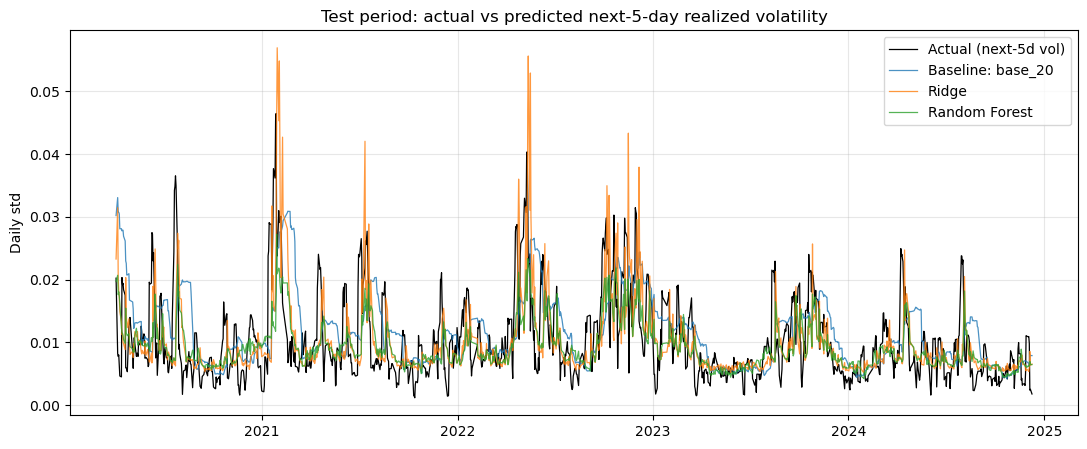

In [16]:
best_model = res["MAE"].idxmin()
print("Best model by MAE:", best_model)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(preds.index, preds["actual"], color="black", lw=0.9, label="Actual (next-5d vol)")
ax.plot(preds.index, preds[best_base], lw=0.9, alpha=0.8, label=f"Baseline: {best_base}")
ax.plot(preds.index, preds["ridge"], lw=0.9, alpha=0.8, label="Ridge")
ax.plot(preds.index, preds["rf"], lw=0.9, alpha=0.8, label="Random Forest")
ax.set(title="Test period: actual vs predicted next-5-day realized volatility", ylabel="Daily std")
ax.legend()
savefig("07_actual_vs_pred.png")
plt.show()

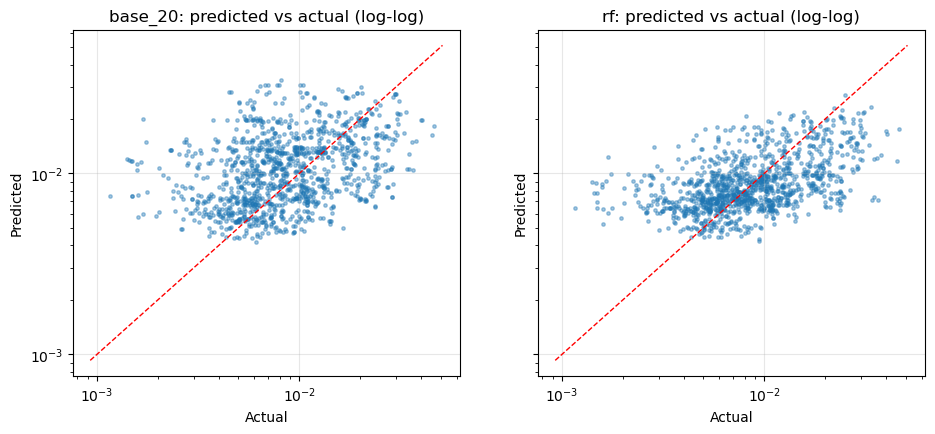

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
lim = [preds["actual"].min() * 0.8, preds["actual"].max() * 1.1]
for ax, m in zip(axes, [best_base, "rf"]):
    ax.scatter(preds["actual"], preds[m], s=6, alpha=0.4)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(title=f"{m}: predicted vs actual (log-log)", xlabel="Actual", ylabel="Predicted")
savefig("08_scatter.png")
plt.show()

## D3. Error analysis
Where does the model make the largest errors? Hypothesis: when volatility rises suddenly (a shock), a model based on past data will underpredict and "arrive late."

In [18]:
abs_err = pd.DataFrame({m: (preds[m] - preds["actual"]).abs() for m in MODELS})
signed = pd.DataFrame({m: preds[m] - preds["actual"] for m in MODELS})  # >0: predicted higher than actual

print("MAE by year:")
display(abs_err.groupby(abs_err.index.year).mean().round(5))

# Target regimes (tertile thresholds taken from train to avoid lookahead into test)
q1, q2 = train["target_vol"].quantile([1 / 3, 2 / 3])
regime = pd.cut(preds["actual"], [-np.inf, q1, q2, np.inf], labels=["low vol", "mid vol", "high vol"])
print("MAE by volatility regime:")
display(abs_err.groupby(regime, observed=True).mean().round(5))
print("Mean bias (predicted − actual) by regime; negative = predicted lower than actual:")
display(signed.groupby(regime, observed=True).mean().round(5))
print("Number of test days by regime:", regime.value_counts().to_dict())

MAE by year:


,base_5,base_20,base_exp,base_ewma,ridge,rf
date,,,,,,
2020,0.00631,0.00673,0.00753,0.00691,0.00486,0.00452
2021,0.00611,0.00675,0.00784,0.00657,0.00539,0.00483
2022,0.00653,0.00577,0.00633,0.00574,0.00604,0.00500
2023,0.00416,0.00379,0.00681,0.00401,0.00340,0.00323
2024,0.00406,0.00377,0.00775,0.00368,0.00317,0.00299


MAE by volatility regime:


,base_5,base_20,base_exp,base_ewma,ridge,rf
actual,,,,,,
low vol,0.00388,0.00503,0.00997,0.00558,0.00301,0.00300
mid vol,0.00448,0.00423,0.00554,0.00404,0.00299,0.00240
high vol,0.00925,0.00755,0.00592,0.00710,0.00958,0.00862


Mean bias (predicted − actual) by regime; negative = predicted lower than actual:


,base_5,base_20,base_exp,base_ewma,ridge,rf
actual,,,,,,
low vol,0.00311,0.00493,0.00997,0.00557,0.00298,0.00291
mid vol,0.00085,0.00224,0.00554,0.00271,0.00008,-0.00024
high vol,-0.00575,-0.00593,-0.00549,-0.00577,-0.00607,-0.00817


Number of test days by regime: {'mid vol': 468, 'low vol': 424, 'high vol': 282}


Top 10 largest error days for rf:


,actual,base_20,rf
date,,,
2020-07-21,0.03422,0.01065,0.00716
2020-07-22,0.03486,0.01056,0.00738
2020-07-23,0.03654,0.01049,0.00711
2020-07-24,0.03499,0.01280,0.01201
2021-01-22,0.03770,0.01519,0.01261
2021-01-25,0.03619,0.01499,0.01216
2021-01-26,0.04533,0.01636,0.01176
2021-01-27,0.04648,0.01825,0.01760
2022-05-10,0.03994,0.01969,0.01728


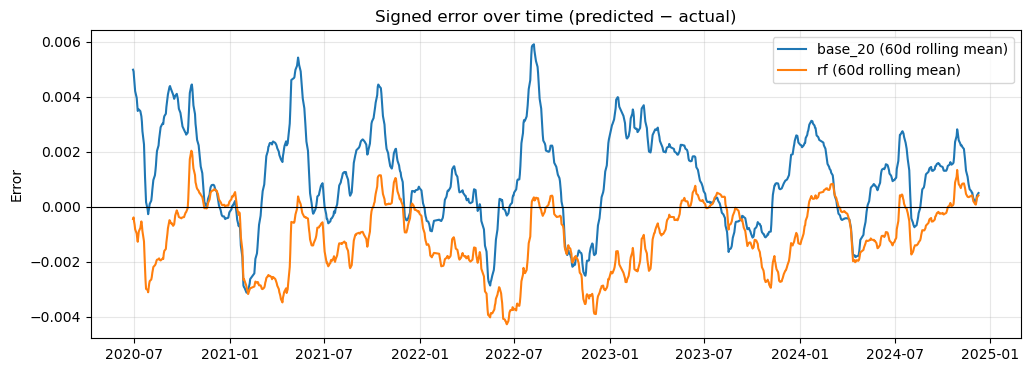

In [19]:
worst = abs_err[best_model].nlargest(10).index
print(f"Top 10 largest error days for {best_model}:")
display(preds.loc[worst, ["actual", best_base, best_model]].sort_index().round(5))

fig, ax = plt.subplots()
for m in dict.fromkeys([best_base, best_model]):
    ax.plot(signed.index, signed[m].rolling(60).mean(), label=f"{m} (60d rolling mean)")
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Signed error over time (predicted − actual)", ylabel="Error")
ax.legend()
savefig("09_bias_over_time.png")
plt.show()

## D4. Model interpretation (for understanding only; not causal conclusions)

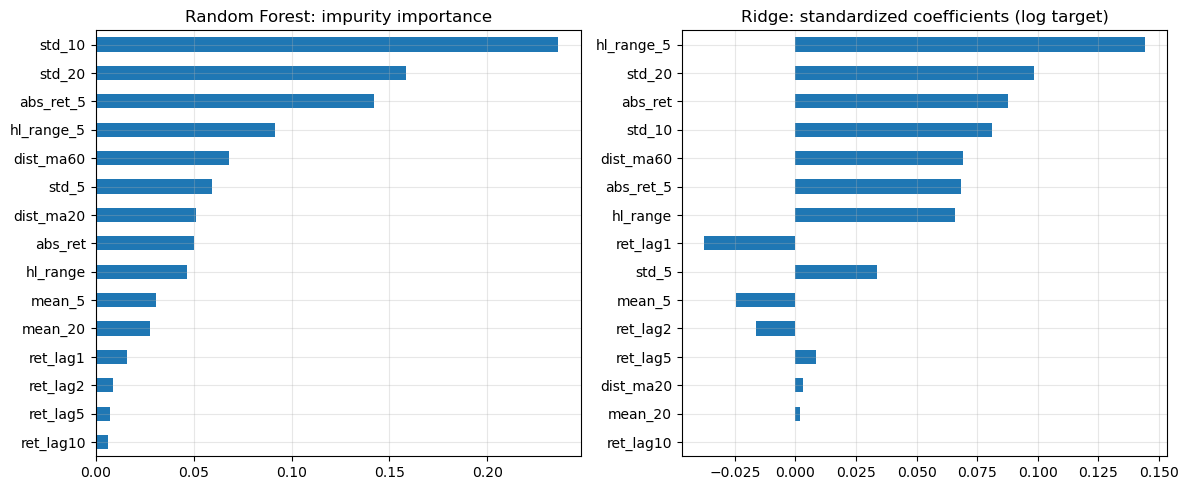

In [20]:
rf_imp = pd.Series(unwrap(final_rf).feature_importances_, index=FEATURES).sort_values()
ridge_coef = pd.Series(unwrap(final_ridge).named_steps["ridge"].coef_, index=FEATURES)
ridge_coef = ridge_coef.reindex(ridge_coef.abs().sort_values().index)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rf_imp.plot.barh(ax=axes[0], title="Random Forest: impurity importance")
ridge_coef.plot.barh(ax=axes[1], title="Ridge: standardized coefficients" + (" (log target)" if LOG_TARGET else ""))
plt.tight_layout()
savefig("10_feature_importance.png")
plt.show()

## D5. Conclusions (write after reviewing the results)
Answer using the figures in the tables above:

1. **RQ3:** Which baseline performs best? Is R²_oos positive (does it outperform the constant forecast)?
2. **RQ4:** Do Ridge / RF outperform the best baseline on **both MAE and RMSE**? By what percentage? Is the improvement consistent across test years, or driven by only 1–2 periods?
3. **Errors:** In which regime does the model make the largest errors, and is its bias positive or negative? Is this related to shocks?
4. **Interpretation:** Which feature is most important? Is that consistent with volatility clustering?
5. **Limitations:** Only one VN-Index series, a single test period, changing regimes, and no transaction costs or live trading evaluation.

If ML only marginally outperforms the baseline or does not outperform it, report that accurately. This is a valid and fairly common result for volatility.

*This is an educational research project, not investment advice.*